# P1.06 — Do the conclusions depend on how affordability is defined?

**Question:** M1 (which indicators best capture affordability, and how do conclusions change under alternative
definitions?). Every phase-1 result uses one definition: price-to-income (PTI) = the median sale price per m² times the
census mean size of occupied dwellings, over the median income per tax household. Here the base is replaced, one choice
at a time:

* **fixed 100 m² dwelling** instead of the municipality's mean size (removes the change in dwelling size between censuses);
* **mean income** instead of the median;
* **bank appraisals** (INE, per m²) instead of transaction prices (a different source, available every year);
* **existing dwellings only** (new builds excluded; prices for this category start in 2019);
* **rent instead of purchase** (rent-to-income, 2020-2024);
* **mortgage burden**, which adds the rate.

Two things are compared across municipalities: the **ranking** (Spearman rank correlation of 2024 levels and of changes)
and the **direction** (share where affordability worsened, same sign as the base).

In [1]:
import pandas as pd

from pthousing.analysis import descriptive as desc
from pthousing.features import affordability as aff
from pthousing.viz import charts, dashboard, style

style.apply_style()
panel = dashboard.load_panel()
panel["pti_valuation"] = aff.price_to_income(
    panel["valuation_sqm_eur"], panel["dwelling_area_sqm"], panel["income_median_eur"]
)
panel["pti_existing"] = aff.price_to_income(
    panel["price_existing_sqm_eur"], panel["dwelling_area_sqm"], panel["income_median_eur"]
)
others = {
    "Fixed 100 m² dwelling": ("pti_years_100sqm", 2016, 2024),
    "Mean instead of median income": ("pti_years_mean_income", 2016, 2024),
    "Bank appraisals instead of sales": ("pti_valuation", 2016, 2024),
    "Existing dwellings only": ("pti_existing", 2019, 2024),
    "Rent instead of purchase": ("rti_pct", 2020, 2024),
    "Mortgage burden (adds the rate)": ("mortgage_burden_pct", 2016, 2024),
}
table = desc.compare_definitions(panel, "pti_years", others, level_year=2024)
style.save_table(table.round(3), "p1", "indicator_robustness")
table.round(2)

,definition,window,level_municipalities_n,rank_corr_level,change_municipalities_n,rank_corr_change,same_sign_pct,top20_shared,worse_pct,base_worse_pct,median_change_pct,base_median_change_pct
0,Fixed 100 m² dwelling,2016-2024,299,0.99,296,1.00,95.27,16,70.27,75.00,16.72,19.46
1,Mean instead of median income,2016-2024,299,1.00,296,1.00,94.59,16,80.41,75.00,24.97,19.46
2,Bank appraisals instead of sales,2016-2024,253,0.92,198,0.84,83.33,14,86.87,84.34,22.11,27.09
3,Existing dwellings only,2019-2024,297,0.99,271,0.91,92.25,19,73.80,75.65,18.90,18.33
4,Rent instead of purchase,2020-2024,212,0.90,191,0.43,76.44,14,85.34,76.44,13.69,13.13
5,Mortgage burden (adds the rate),2016-2024,299,1.00,296,1.00,79.39,20,95.61,75.00,64.12,19.46


## Step 1 — The ranking of places
Levels in 2024 rank almost identically whatever the choice (rank correlation 0.99 for size, income and price type, 0.92
for appraisals, 0.90 for rents). The mortgage burden is the same ranking by construction: one national rate multiplies
every municipality. Rankings of **change** are less stable: appraisals 0.84, but rent-based affordability moves differently
from purchase affordability (0.43).

## Step 2 — The direction and size of the change
Median of each municipality's own change since 2016 (2016 = 100), for the four price-to-income variants that cover 2016-2024.

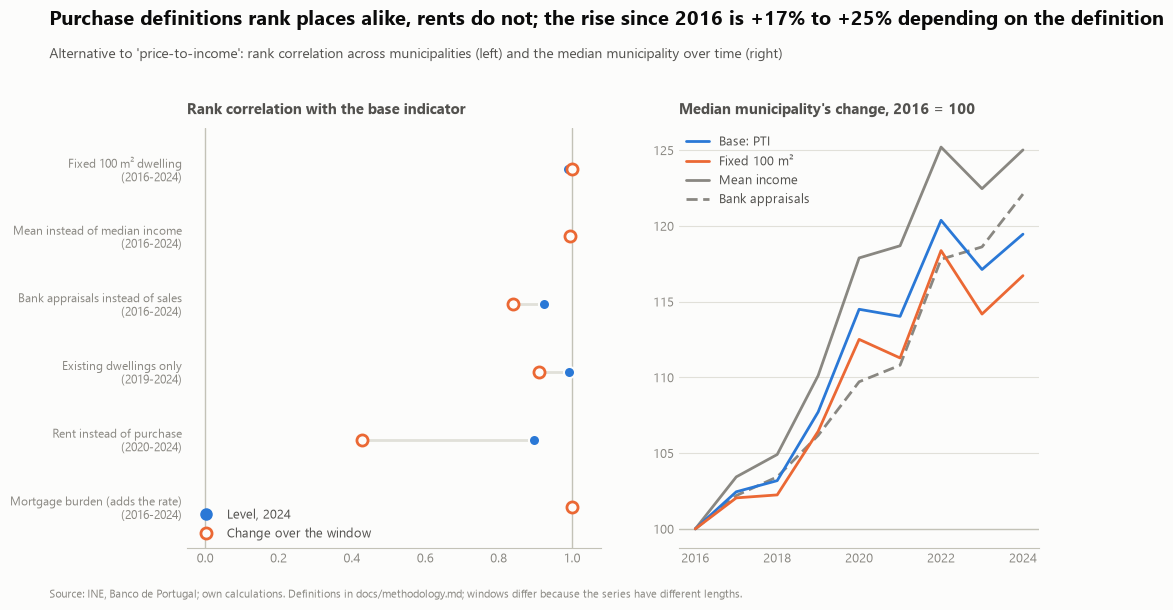

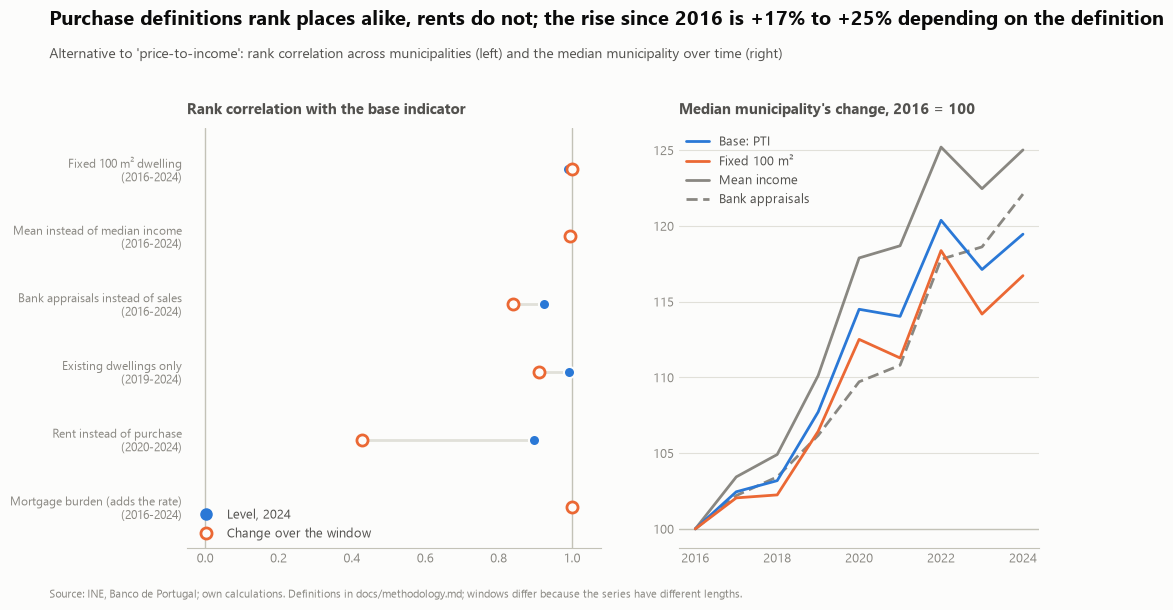

In [2]:
variants = {
    "Base: PTI": "pti_years",
    "Fixed 100 m²": "pti_years_100sqm",
    "Mean income": "pti_years_mean_income",
    "Bank appraisals": "pti_valuation",
}
# each municipality is compared with its own 2016 value, so the median does not change identity from year to year
trends = pd.DataFrame(
    {
        label: 100
        * (
            panel[panel["year"].between(2016, 2024)]
            .pivot(index="muni_code", columns="year", values=column)
            .pipe(lambda w: w.div(w[2016], axis=0))
            .median()
        )
        for label, column in variants.items()
    }
)
style.save_table(trends.round(1).reset_index(), "p1", "indicator_robustness_trends")
fig = charts.indicator_robustness(table, trends, "price-to-income")
style.save_fig(fig, "p1", "indicator_robustness")
fig

## Step 3 — Where definitions part ways
The municipalities where the 2016-2024 change of price-to-income has a different sign with a fixed 100 m² dwelling: the
base counts the change in the size of occupied homes (census 2011 to 2021, interpolated) as a change in affordability.

In [3]:
wide = panel.pivot(index="muni_code", columns="year", values=["pti_years", "pti_years_100sqm"])
base_change = wide["pti_years"][2024] / wide["pti_years"][2016] - 1
fixed_change = wide["pti_years_100sqm"][2024] / wide["pti_years_100sqm"][2016] - 1
differ = (base_change > 0) != (fixed_change > 0)
differ &= base_change.notna() & fixed_change.notna()
names = panel.drop_duplicates("muni_code").set_index("muni_code")[["muni_name", "district"]]
split = (
    names.join(base_change.rename("pti_change_pct").mul(100).round(1))
    .join(fixed_change.rename("pti_100sqm_change_pct").mul(100).round(1))[differ]
    .sort_values("pti_change_pct")
)
style.save_table(split.reset_index(), "p1", "indicator_robustness_sign_differs")
print(
    f"{int(differ.sum())} of {int((base_change.notna() & fixed_change.notna()).sum())} municipalities change sign"
)
split.head(12)

14 of 296 municipalities change sign


,muni_name,district,pti_change_pct,pti_100sqm_change_pct
muni_code,,,,
0310,Terras de Bouro,Braga,0.6,-2.8
0906,Gouveia,Guarda,1.1,-2.4
1604,Monção,Viana do Castelo,1.1,-1.1
0202,Almodôvar,Beja,1.2,-0.9
1206,Crato,Portalegre,1.2,-3.2
0703,Borba,Évora,1.4,-2.0
0210,Moura,Beja,1.5,-0.5
0504,Fundão,Castelo Branco,1.7,-0.1
0502,Castelo Branco,Castelo Branco,1.8,-0.4


## Key numbers

In [4]:
t = table.set_index("definition")
print(
    t[["rank_corr_level", "rank_corr_change", "same_sign_pct", "worse_pct", "base_worse_pct"]]
    .round(2)
    .to_string()
)
e = trends.iloc[-1] - 100
print("median change 2016-2024 (%):", e.round(1).to_dict())

                                  rank_corr_level  rank_corr_change  same_sign_pct  worse_pct  base_worse_pct
definition                                                                                                   
Fixed 100 m² dwelling                        0.99              1.00          95.27      70.27           75.00
Mean instead of median income                1.00              1.00          94.59      80.41           75.00
Bank appraisals instead of sales             0.92              0.84          83.33      86.87           84.34
Existing dwellings only                      0.99              0.91          92.25      73.80           75.65
Rent instead of purchase                     0.90              0.43          76.44      85.34           76.44
Mortgage burden (adds the rate)              1.00              1.00          79.39      95.61           75.00
median change 2016-2024 (%): {'Base: PTI': 19.5, 'Fixed 100 m²': 16.7, 'Mean income': 25.0, 'Bank appraisals': 22.1}
